[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/notebooks/08_probability.ipynb)

<div dir="rtl">

# جلسه ۸: احتمال برای علم داده

**اهداف این جلسه**

- مفاهیم پایه: آزمایش تصادفی، فضای نمونه، پیشامد
- **شبیه‌سازی** به‌عنوان ابزار محاسبه‌ی احتمال
- قانون اعداد بزرگ
- احتمال شرطی، استقلال و **قضیه‌ی بیز**
- متغیر تصادفی، امید ریاضی و واریانس
- توزیع‌های مهم: برنولی، دوجمله‌ای، پواسون، یکنواخت، نرمال و نمایی
- کار با `scipy.stats`: تابع چگالی/جرم (pdf/pmf)، تابع توزیع تجمعی (cdf) و نمونه‌گیری

احتمال، زبان **عدم قطعیت** است. هر جا داده داریم، نویز و تصادف هم داریم؛ آمار (جلسه‌ی بعد) و یادگیری ماشین (ترم بعد) هر دو روی احتمال بنا شده‌اند.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(1405)

<div dir="rtl">

## ۱. مفاهیم پایه

- **آزمایش تصادفی**: فرایندی که نتیجه‌اش از قبل معلوم نیست (پرتاب تاس).
- **فضای نمونه** $S$: مجموعه‌ی همه‌ی نتایج ممکن، $S = \{1, 2, 3, 4, 5, 6\}$.
- **پیشامد** $A$: زیرمجموعه‌ای از فضای نمونه، مثلاً «عدد زوج» $= \{2, 4, 6\}$.
- اگر همه‌ی نتایج هم‌شانس باشند: $P(A) = \dfrac{|A|}{|S|}$

قواعد اصلی:

- $0 \le P(A) \le 1$
- $P(\text{not } A) = 1 - P(A)$
- $P(A \cup B) = P(A) + P(B) - P(A \cap B)$

</div>

<div dir="rtl">

## ۲. شبیه‌سازی: محاسبه‌ی احتمال با کامپیوتر

وقتی محاسبه‌ی دقیق سخت است، آزمایش را میلیون‌ها بار شبیه‌سازی می‌کنیم و **فراوانی نسبی** را حساب می‌کنیم. احتمال اینکه جمع دو تاس ۷ شود:

</div>

simulated P(sum = 7) = 0.1667
exact     P(sum = 7) = 0.1667


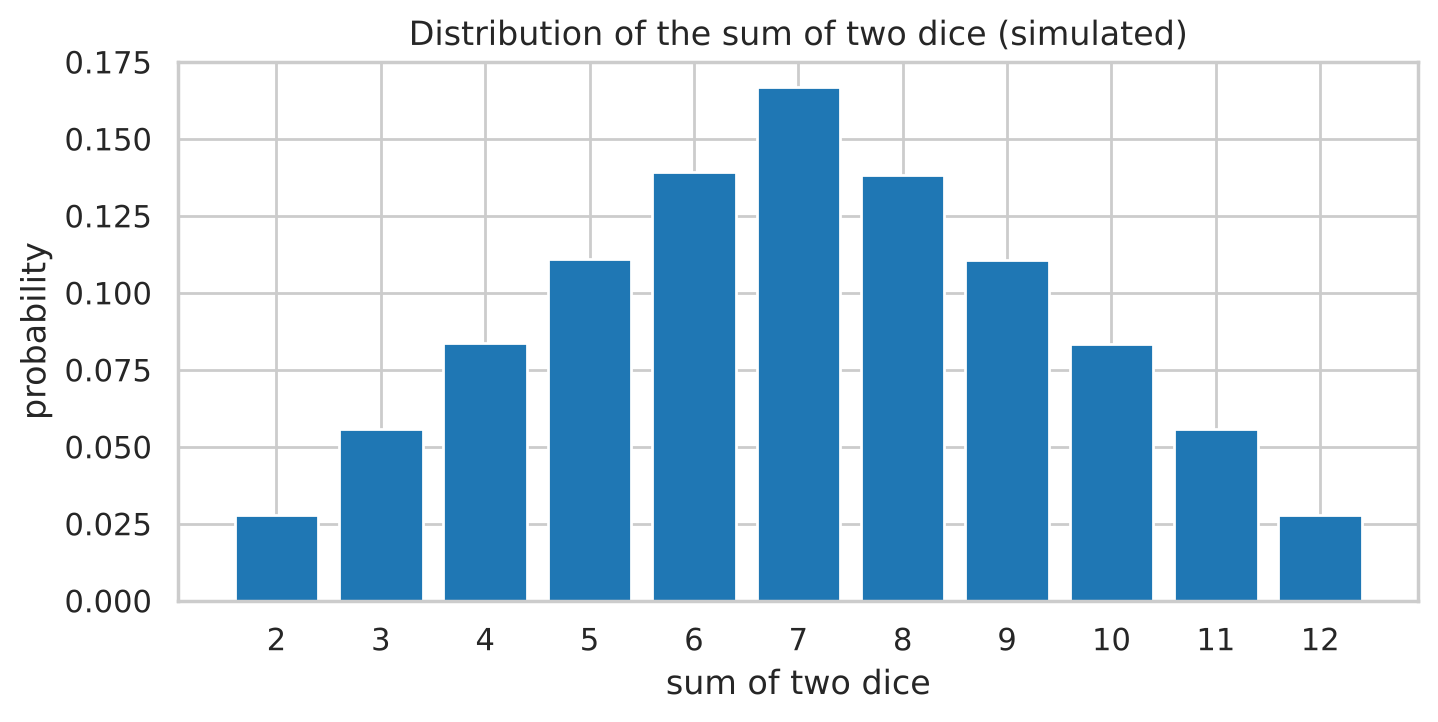

In [2]:
n = 1_000_000
dice = rng.integers(1, 7, size=(n, 2))
total = dice.sum(axis=1)

print(f"simulated P(sum = 7) = {(total == 7).mean():.4f}")
print(f"exact     P(sum = 7) = {6 / 36:.4f}")

counts = pd.Series(total).value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index, counts.values, color="tab:blue")
ax.set_xticks(range(2, 13))
ax.set_xlabel("sum of two dice")
ax.set_ylabel("probability")
ax.set_title("Distribution of the sum of two dice (simulated)")
plt.show()

<div dir="rtl">

## ۳. قانون اعداد بزرگ

هرچه تعداد تکرار بیشتر شود، فراوانی نسبی به احتمال واقعی **نزدیک‌تر** می‌شود. این همان دلیلی است که شبیه‌سازی کار می‌کند، و همان دلیلی است که نتیجه‌گیری از نمونه‌ی کوچک خطرناک است.

</div>

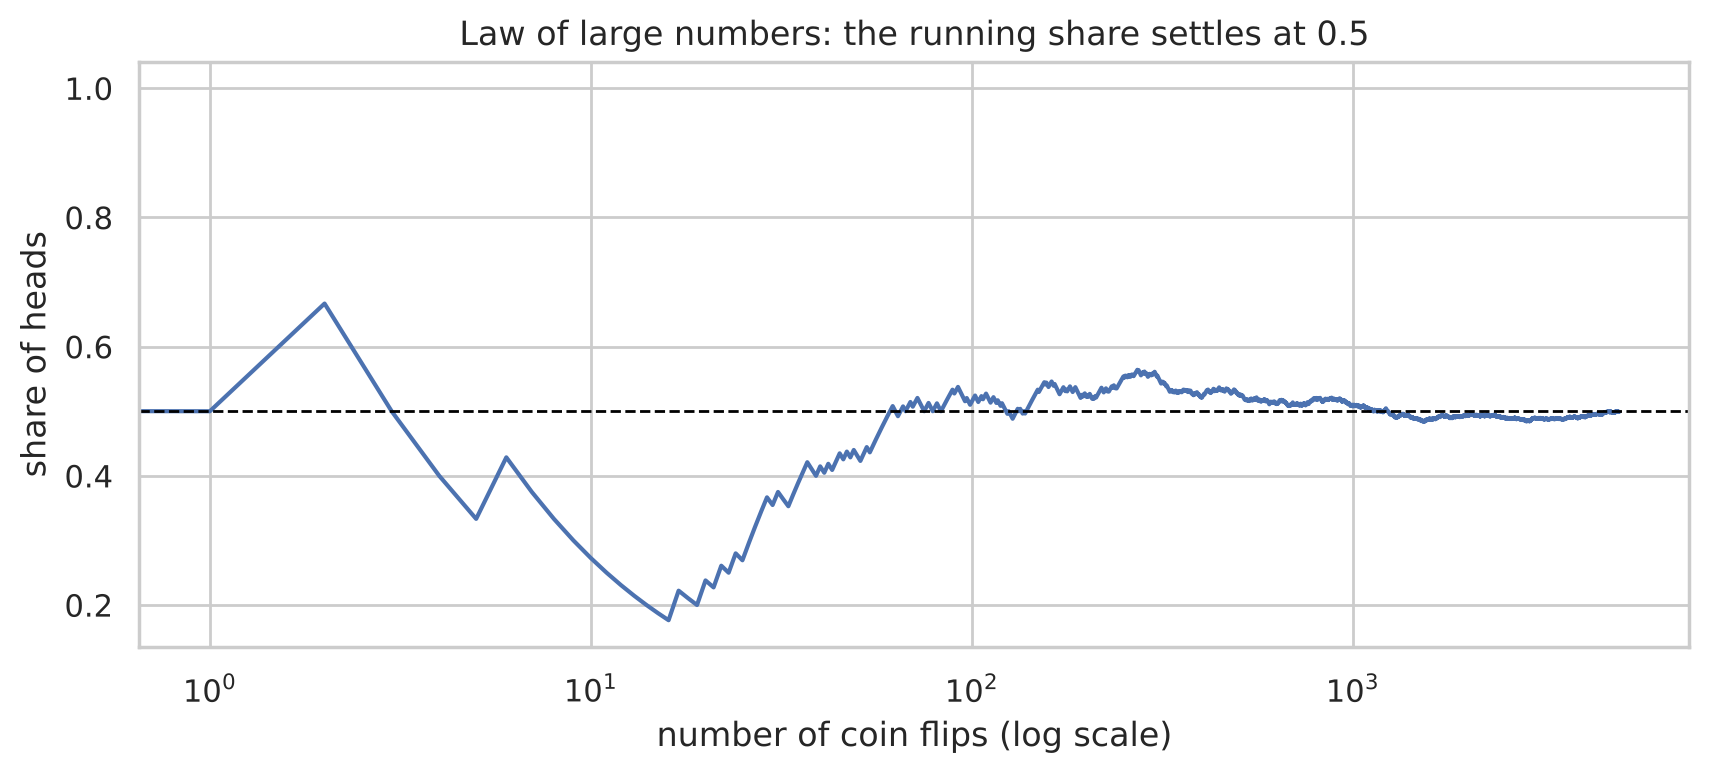

In [3]:
flips = rng.integers(0, 2, size=5000)                 # 1 = heads
running = flips.cumsum() / np.arange(1, len(flips) + 1)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(running, linewidth=1.5)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("number of coin flips (log scale)")
ax.set_ylabel("share of heads")
ax.set_title("Law of large numbers: the running share settles at 0.5")
plt.show()

<div dir="rtl">

### یک مثال غیرشهودی: مسئله‌ی تولد

در یک کلاس ۲۳ نفره، احتمال اینکه حداقل دو نفر **تاریخ تولد یکسان** داشته باشند چقدر است؟ بیشتر افراد حدس می‌زنند حدود ۵٪. بیایید شبیه‌سازی کنیم:

</div>

In [4]:
def shared_birthday_prob(k, trials=50_000):
    days = rng.integers(0, 365, size=(trials, k))
    sorted_days = np.sort(days, axis=1)
    has_pair = (np.diff(sorted_days, axis=1) == 0).any(axis=1)
    return has_pair.mean()

def exact(k):
    return 1 - np.prod((365 - np.arange(k)) / 365)

for k in [10, 23, 30, 50]:
    print(f"class of {k:2d}: simulated {shared_birthday_prob(k):.3f}, exact {exact(k):.3f}")

class of 10: simulated 0.118, exact 0.117
class of 23: simulated 0.506, exact 0.507
class of 30: simulated 0.709, exact 0.706


class of 50: simulated 0.970, exact 0.970


<div dir="rtl">

بیش از ۵۰٪! دلیل: در یک کلاس ۲۳ نفره ۲۵۳ **جفت** مختلف وجود دارد، نه ۲۳. شهود ما در احتمال اغلب اشتباه می‌کند و شبیه‌سازی یک راه مطمئن برای بررسی آن است.

## ۴. احتمال شرطی و استقلال

احتمال $A$ به شرط اینکه بدانیم $B$ رخ داده است:

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}$$

دو پیشامد **مستقل**‌اند اگر دانستن یکی، احتمال دیگری را تغییر ندهد: $P(A \mid B) = P(A)$.

بیایید روی داده‌ی واقعی تایتانیک ببینیم: آیا زنده ماندن از جنسیت مستقل بود؟

</div>

In [5]:
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"
titanic = pd.read_csv(DATA_URL + "titanic.csv")

p_survive = titanic["survived"].mean()
p_survive_given_female = titanic.loc[titanic["sex"] == "female", "survived"].mean()
p_survive_given_male = titanic.loc[titanic["sex"] == "male", "survived"].mean()

print(f"P(survived)          = {p_survive:.3f}")
print(f"P(survived | female) = {p_survive_given_female:.3f}")
print(f"P(survived | male)   = {p_survive_given_male:.3f}")

P(survived)          = 0.384
P(survived | female) = 0.742
P(survived | male)   = 0.189


In [6]:
pd.crosstab(titanic["sex"], titanic["survived"], normalize="all", margins=True).round(3)

survived,0,1,All
sex,,,
female,0.091,0.262,0.352
male,0.525,0.122,0.648
All,0.616,0.384,1.000


<div dir="rtl">

احتمال زنده ماندن به شرط زن بودن حدود ۷۴٪ و به شرط مرد بودن حدود ۱۹٪ است؛ پس این دو پیشامد **مستقل نیستند** (قانون «اول زنان و کودکان»). در جلسه‌ی بعد می‌بینیم چطور با آزمون آماری بررسی کنیم که چنین تفاوتی تصادفی نیست.

## ۵. قضیه‌ی بیز

قضیه‌ی بیز می‌گوید چطور با دیدن شواهد جدید، باورمان را به‌روز کنیم:

$$P(H \mid E) = \frac{P(E \mid H)\, P(H)}{P(E)}$$

- $P(H)$: احتمال **پیشین** (قبل از دیدن شواهد)
- $P(E \mid H)$: **درست‌نمایی** (احتمال دیدن شواهد اگر فرضیه درست باشد)
- $P(H \mid E)$: احتمال **پسین** (بعد از دیدن شواهد)

**مثال: آزمایش تشخیصی.** یک بیماری در ۱٪ جمعیت وجود دارد. آزمایشی برای آن داریم که:

- اگر فرد بیمار باشد، ۹۵٪ مواقع نتیجه مثبت می‌دهد (حساسیت).
- اگر فرد سالم باشد، ۵٪ مواقع به اشتباه نتیجه مثبت می‌دهد (مثبت کاذب).

نتیجه‌ی آزمایش شما مثبت شده است. احتمال اینکه واقعاً بیمار باشید چقدر است؟

</div>

In [7]:
prior = 0.01
sensitivity = 0.95
false_positive = 0.05

p_positive = sensitivity * prior + false_positive * (1 - prior)
posterior = sensitivity * prior / p_positive
print(f"P(sick | positive) = {posterior:.3f}")

P(sick | positive) = 0.161


<div dir="rtl">

فقط حدود **۱۶٪**! این نتیجه برای بیشتر افراد (حتی بسیاری از پزشکان) شگفت‌آور است. یک «جمعیت فرضی» ۱۰٬۰۰۰ نفره آن را روشن می‌کند:

</div>

In [8]:
population = 10_000
sick = population * prior
healthy = population - sick
true_pos = sick * sensitivity
false_pos = healthy * false_positive

pd.DataFrame({
    "people": [sick, healthy],
    "test positive": [true_pos, false_pos],
}, index=["sick", "healthy"]).astype(int)

,people,test positive
sick,100,95
healthy,9900,495


<div dir="rtl">

از ۵۹۰ نفر با نتیجه‌ی مثبت، فقط ۹۵ نفر بیمارند. چون افراد سالم **خیلی بیشترند**، حتی ۵٪ خطا روی آن‌ها تعداد زیادی مثبت کاذب می‌سازد. نادیده گرفتن احتمال پیشین را **خطای نرخ پایه (Base Rate Fallacy)** می‌گویند.

همین منطق در یادگیری ماشین هم مهم است: یک مدل تشخیص تقلب با دقت ظاهری بالا، روی داده‌ای که فقط ۰٫۱٪ آن تقلب است، می‌تواند تعداد زیادی هشدار کاذب تولید کند.

نمودار زیر نشان می‌دهد احتمال پسین چقدر به نرخ پایه وابسته است:

</div>

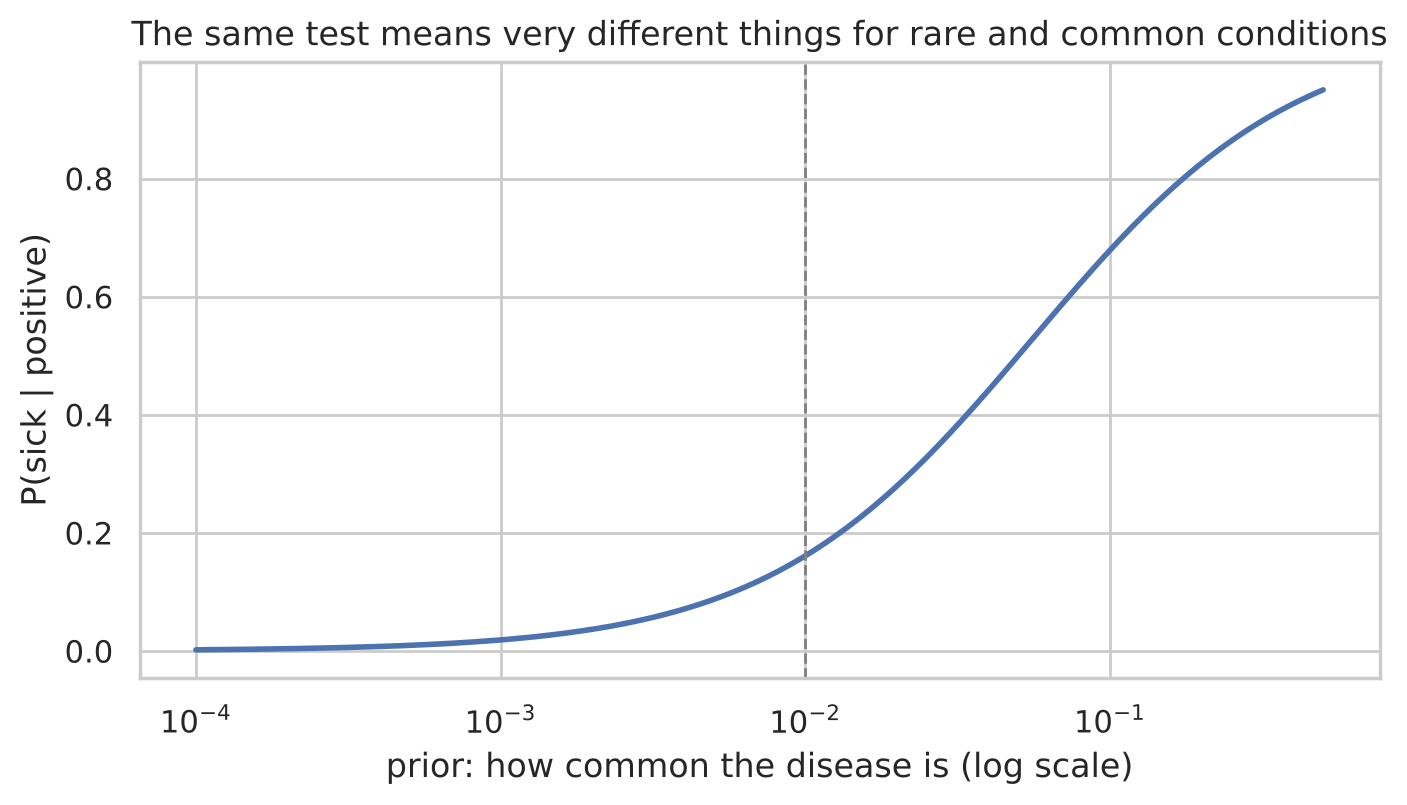

In [9]:
priors = np.logspace(-4, -0.3, 200)
posteriors = sensitivity * priors / (sensitivity * priors + false_positive * (1 - priors))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(priors, posteriors, linewidth=2)
ax.set_xscale("log")
ax.set_xlabel("prior: how common the disease is (log scale)")
ax.set_ylabel("P(sick | positive)")
ax.set_title("The same test means very different things for rare and common conditions")
ax.axvline(0.01, color="gray", linestyle="--", linewidth=1)
plt.show()

<div dir="rtl">

## ۶. متغیر تصادفی، امید ریاضی و واریانس

**متغیر تصادفی** به هر نتیجه‌ی آزمایش یک عدد نسبت می‌دهد.

- **امید ریاضی** (میانگین بلندمدت): $E[X] = \sum_x x\, P(X = x)$
- **واریانس** (میزان پراکندگی): $\text{Var}(X) = E[(X - E[X])^2]$
- **انحراف معیار**: $\sigma = \sqrt{\text{Var}(X)}$

**مثال: یک بازی شانسی.** با پرداخت ۱۰ هزار تومان یک تاس می‌اندازید. اگر ۶ بیاید ۵۰ هزار تومان می‌گیرید، در غیر این صورت هیچ. آیا این بازی به نفع شماست؟

</div>

In [10]:
outcomes = np.array([50 - 10, -10])          # net gain in thousand Toman
probs = np.array([1 / 6, 5 / 6])

expected = (outcomes * probs).sum()
variance = (((outcomes - expected) ** 2) * probs).sum()
print(f"E[gain] = {expected:.2f} thousand Toman per game")
print(f"SD      = {np.sqrt(variance):.2f}")

games = rng.choice(outcomes, size=10_000, p=probs)
print(f"average over 10,000 simulated games: {games.mean():.2f}")

E[gain] = -1.67 thousand Toman per game
SD      = 18.63
average over 10,000 simulated games: -2.06


<div dir="rtl">

امید ریاضی منفی است: در بلندمدت، به ازای هر بازی حدود ۱٫۷ هزار تومان ضرر می‌کنید. همه‌ی بازی‌های شانسی که برگزارکننده‌شان سود می‌کند، همین ساختار را دارند.

## ۷. توزیع‌های گسسته

| توزیع | چه چیزی را مدل می‌کند | مثال |
|---|---|---|
| **برنولی** $(p)$ | یک آزمایش با دو نتیجه | کلیک کاربر روی تبلیغ |
| **دوجمله‌ای** $(n, p)$ | تعداد موفقیت در $n$ آزمایش مستقل | تعداد خریدار از ۱۰۰ بازدیدکننده |
| **پواسون** $(\lambda)$ | تعداد رخداد در یک بازه‌ی زمانی | تعداد سفارش در یک ساعت |

در `scipy.stats`، هر توزیع متدهای یکسانی دارد:

- `pmf(k)`: احتمال اینکه دقیقاً $k$ شود (برای توزیع گسسته)
- `cdf(k)`: احتمال اینکه حداکثر $k$ شود
- `rvs(size)`: نمونه‌گیری تصادفی
- `mean()`، `std()`

</div>

In [11]:
# 100 visitors, each buys with probability 0.03
buyers = stats.binom(n=100, p=0.03)
print(f"P(exactly 3 buyers)   = {buyers.pmf(3):.3f}")
print(f"P(at most 1 buyer)    = {buyers.cdf(1):.3f}")
print(f"P(more than 5 buyers) = {1 - buyers.cdf(5):.3f}")
print(f"mean = {buyers.mean():.1f}, sd = {buyers.std():.2f}")

P(exactly 3 buyers)   = 0.227
P(at most 1 buyer)    = 0.195
P(more than 5 buyers) = 0.081
mean = 3.0, sd = 1.71


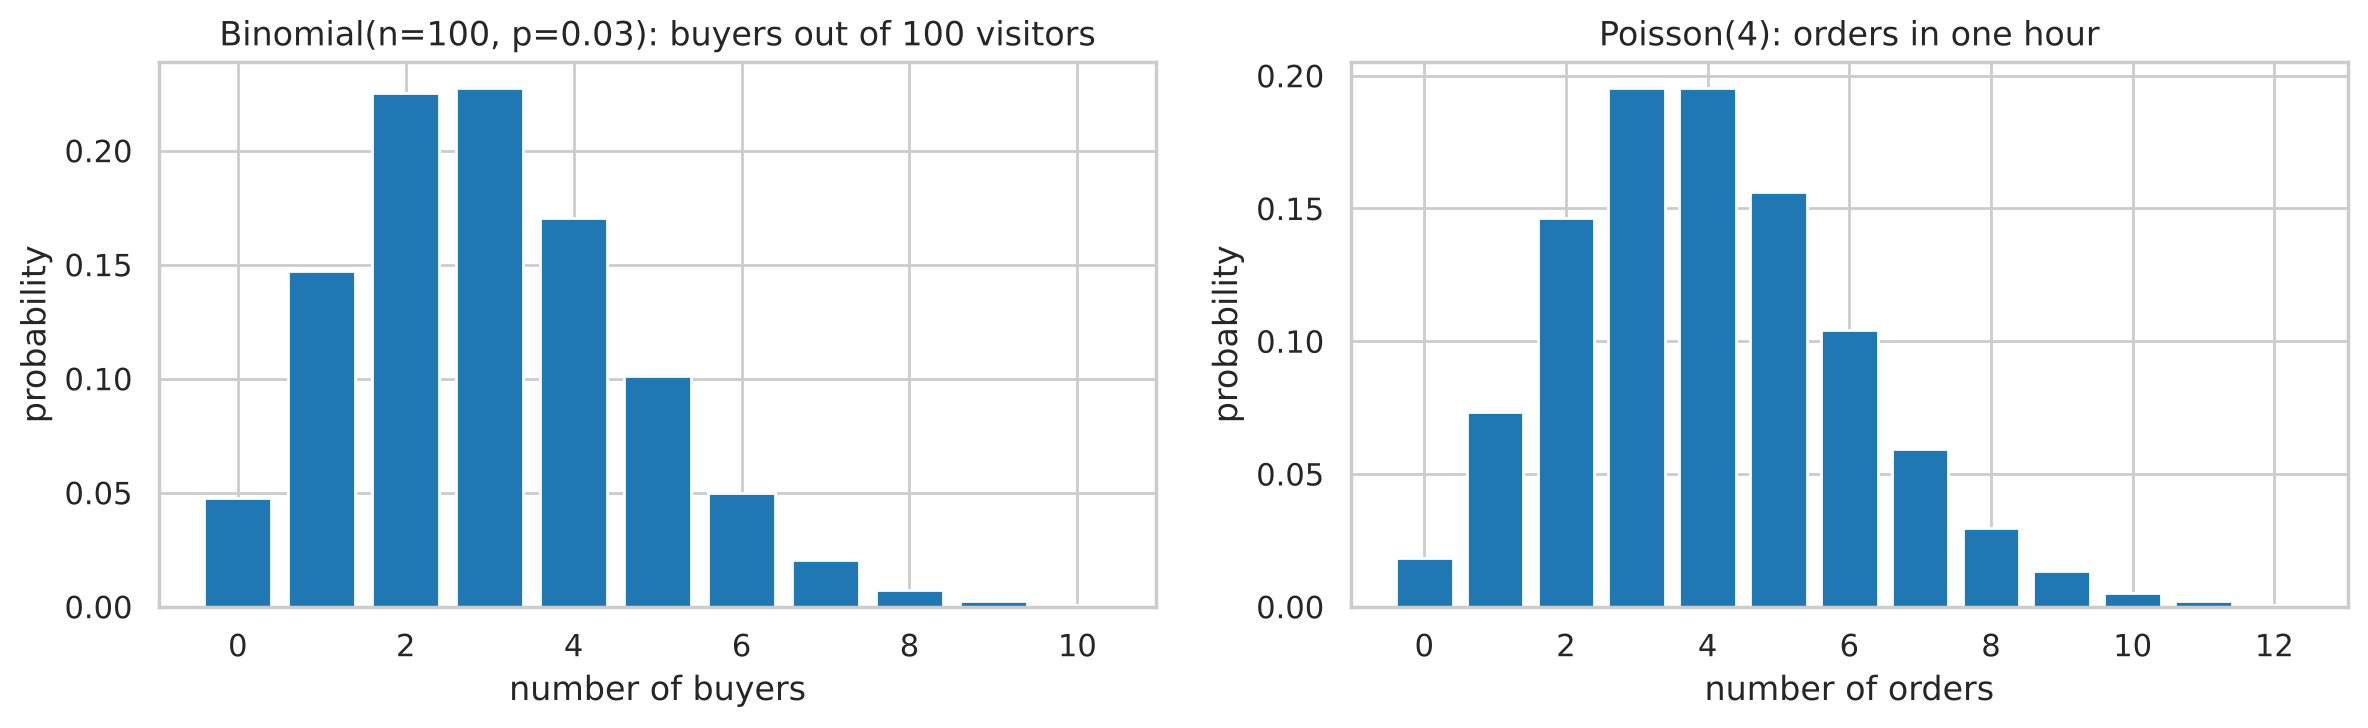

P(no order in an hour)      = 0.018
P(10 or more orders in hour) = 0.0081


In [12]:
# orders arrive at an average rate of 4 per hour
orders_per_hour = stats.poisson(mu=4)
k = np.arange(0, 13)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(np.arange(0, 11), buyers.pmf(np.arange(0, 11)), color="tab:blue")
axes[0].set_title("Binomial(n=100, p=0.03): buyers out of 100 visitors")
axes[0].set_xlabel("number of buyers")
axes[1].bar(k, orders_per_hour.pmf(k), color="tab:blue")
axes[1].set_title("Poisson(4): orders in one hour")
axes[1].set_xlabel("number of orders")
for ax in axes:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

print(f"P(no order in an hour)      = {orders_per_hour.pmf(0):.3f}")
print(f"P(10 or more orders in hour) = {1 - orders_per_hour.cdf(9):.4f}")

<div dir="rtl">

## ۸. توزیع‌های پیوسته

برای متغیر پیوسته، احتمال یک مقدار **دقیق** صفر است؛ احتمال فقط برای **بازه** معنا دارد و برابر مساحت زیر منحنی چگالی (`pdf`) در آن بازه است.

| توزیع | کاربرد |
|---|---|
| **یکنواخت** $U(a, b)$ | همه‌ی مقادیر یک بازه هم‌شانس‌اند |
| **نرمال** $N(\mu, \sigma)$ | مجموع اثرهای کوچک و مستقل زیاد؛ قد، خطای اندازه‌گیری |
| **نمایی** $(\lambda)$ | زمان انتظار تا رخداد بعدی (همراه پواسون) |

### توزیع نرمال و قاعده‌ی ۶۸-۹۵-۹۹٫۷

در توزیع نرمال، حدود ۶۸٪ داده‌ها در فاصله‌ی یک انحراف معیار از میانگین، ۹۵٪ در فاصله‌ی دو انحراف معیار و ۹۹٫۷٪ در فاصله‌ی سه انحراف معیار هستند.

</div>

P(|Z| < 1) = 0.6827
P(|Z| < 2) = 0.9545
P(|Z| < 3) = 0.9973


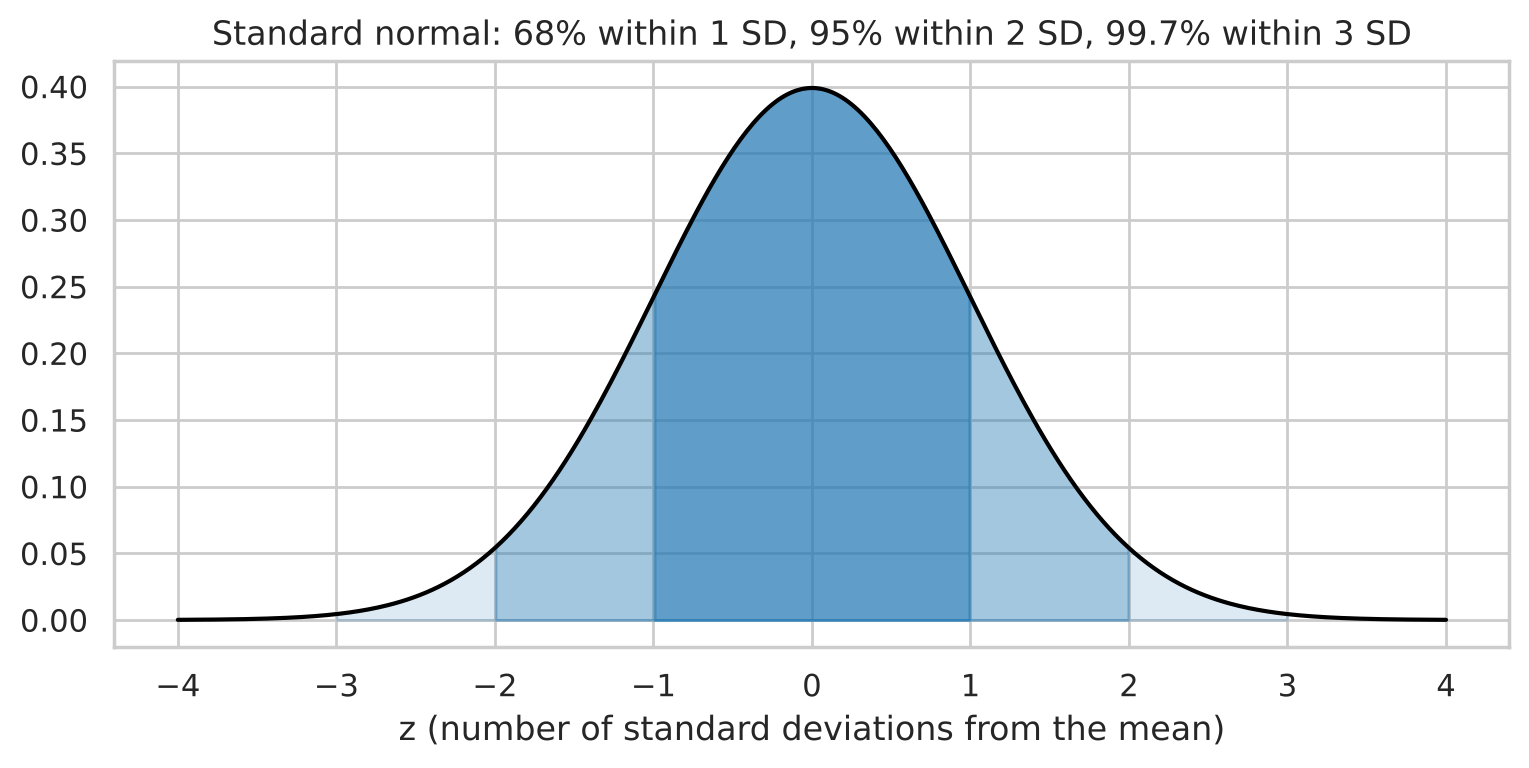

In [13]:
z = stats.norm(0, 1)
for k in [1, 2, 3]:
    print(f"P(|Z| < {k}) = {z.cdf(k) - z.cdf(-k):.4f}")

x = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, z.pdf(x), color="black", linewidth=1.5)
for k, shade in [(3, 0.15), (2, 0.3), (1, 0.5)]:
    mask = np.abs(x) <= k
    ax.fill_between(x[mask], z.pdf(x[mask]), color="tab:blue", alpha=shade)
ax.set_title("Standard normal: 68% within 1 SD, 95% within 2 SD, 99.7% within 3 SD")
ax.set_xlabel("z (number of standard deviations from the mean)")
plt.show()

<div dir="rtl">

**مثال:** قد مردان بزرگسال تقریباً نرمال با میانگین ۱۷۴ و انحراف معیار ۷ سانتی‌متر فرض شود.

- چند درصد بلندتر از ۱۹۰ سانتی‌متر هستند؟
- قد ۹۰٪ افراد زیر چه عددی است؟ (معکوس `cdf` که در scipy به آن `ppf` می‌گویند)

</div>

In [14]:
height = stats.norm(loc=174, scale=7)
print(f"P(height > 190)        = {1 - height.cdf(190):.4f}   (sf gives the same: {height.sf(190):.4f})")
print(f"P(165 < height < 185)  = {height.cdf(185) - height.cdf(165):.3f}")
print(f"90th percentile        = {height.ppf(0.90):.1f} cm")

P(height > 190)        = 0.0111   (sf gives the same: 0.0111)
P(165 < height < 185)  = 0.843
90th percentile        = 183.0 cm


<div dir="rtl">

### توزیع نمایی: زمان انتظار

اگر سفارش‌ها با نرخ ۴ در ساعت (پواسون) برسند، زمان بین دو سفارش متوالی توزیع نمایی با میانگین ۱/۴ ساعت (۱۵ دقیقه) دارد. بیایید این ارتباط را با شبیه‌سازی ببینیم:

</div>

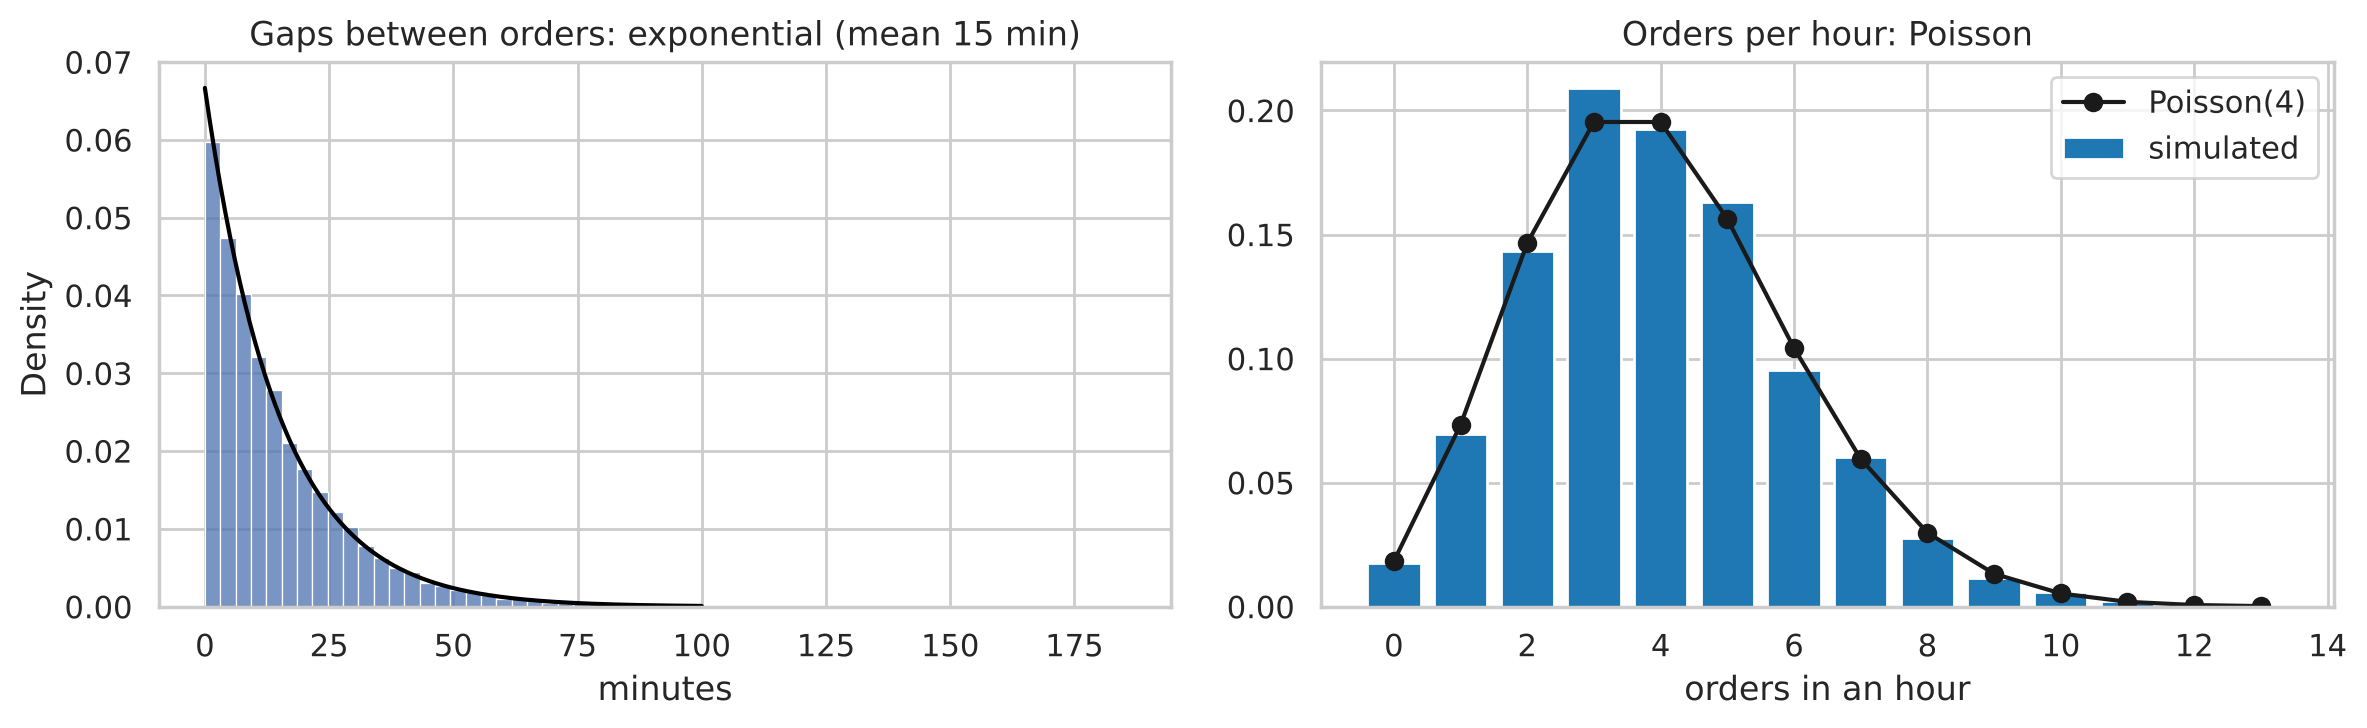

In [15]:
gaps_minutes = rng.exponential(scale=15, size=20_000)       # time between orders
arrival_times = np.cumsum(gaps_minutes)
orders_in_each_hour = np.bincount((arrival_times // 60).astype(int))[:-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(gaps_minutes, bins=60, stat="density", ax=axes[0])
xs = np.linspace(0, 100, 200)
axes[0].plot(xs, stats.expon(scale=15).pdf(xs), color="black")
axes[0].set_title("Gaps between orders: exponential (mean 15 min)")
axes[0].set_xlabel("minutes")

k = np.arange(0, 14)
observed = np.bincount(orders_in_each_hour, minlength=14)[:14] / len(orders_in_each_hour)
axes[1].bar(k, observed, color="tab:blue", label="simulated")
axes[1].plot(k, stats.poisson(4).pmf(k), "ko-", label="Poisson(4)")
axes[1].set_title("Orders per hour: Poisson")
axes[1].set_xlabel("orders in an hour")
axes[1].legend()
plt.tight_layout()
plt.show()

<div dir="rtl">

## ۹. آیا داده‌ی واقعی نرمال است؟

نمودار **Q-Q** چندک‌های داده را با چندک‌های توزیع نرمال مقایسه می‌کند. اگر نقاط روی خط راست باشند، داده تقریباً نرمال است.

</div>

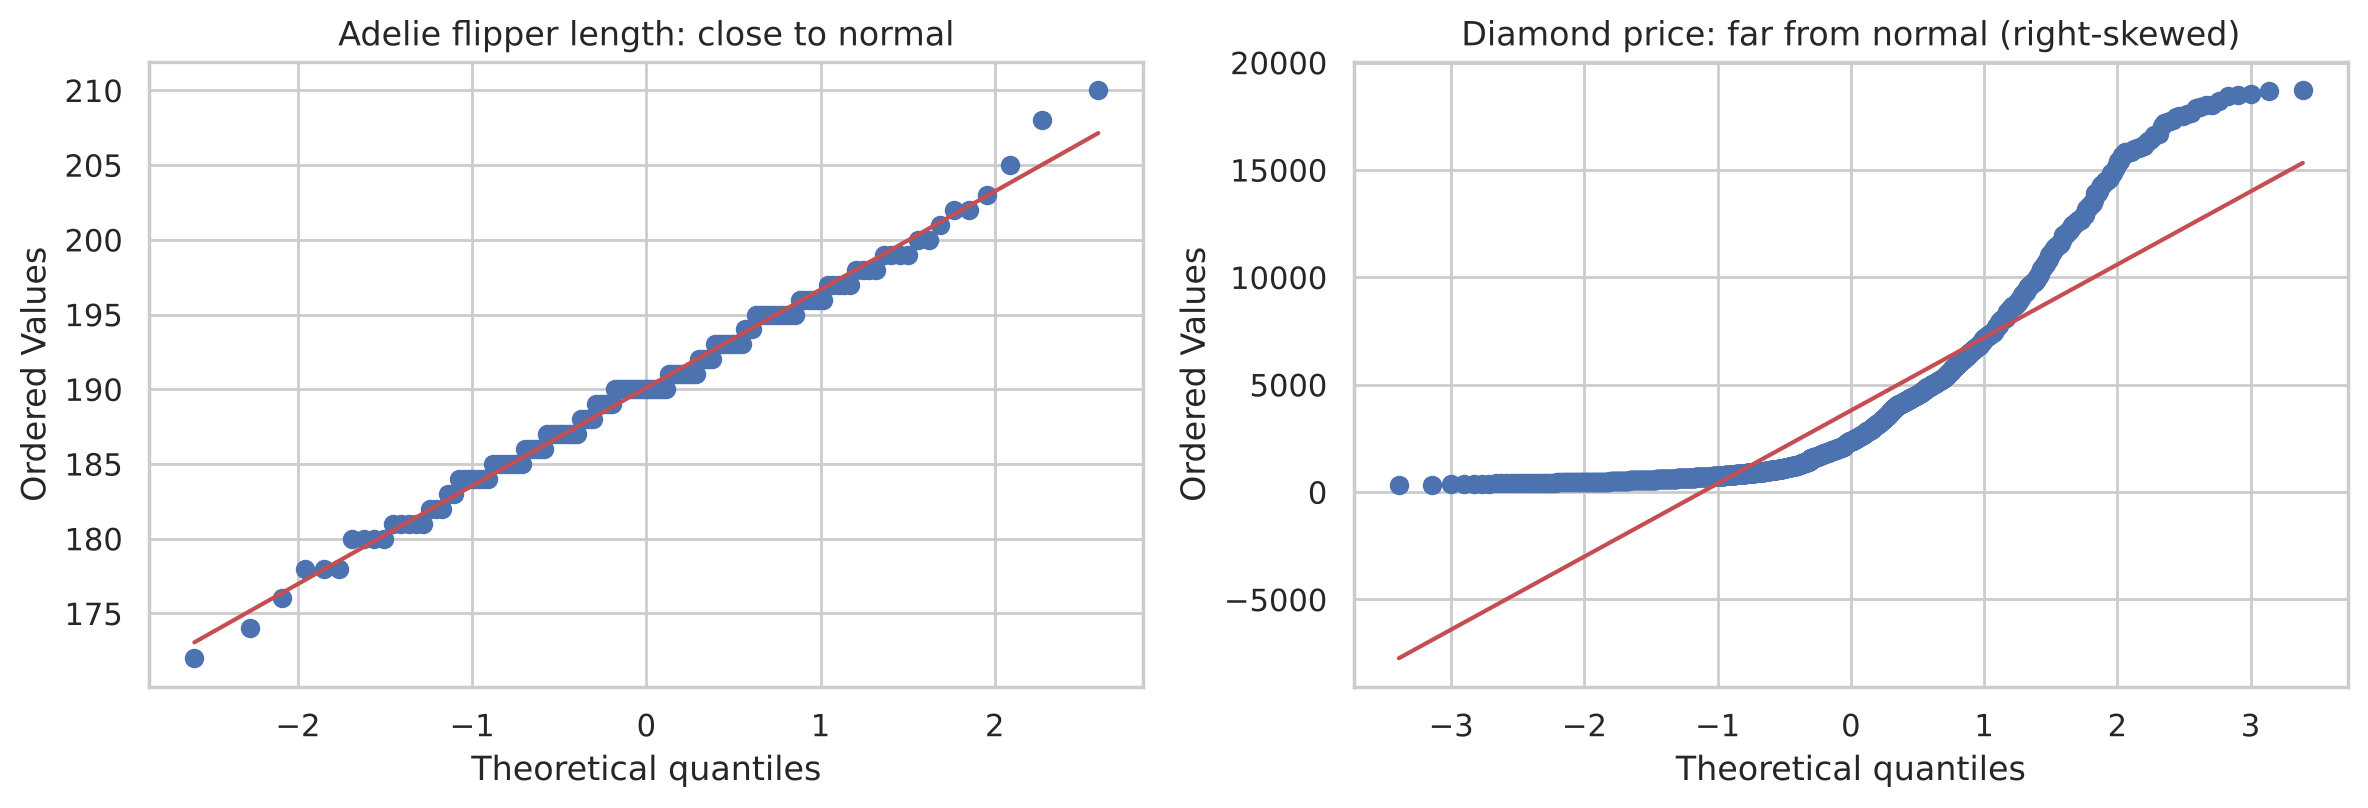

In [16]:
penguins = pd.read_csv(DATA_URL + "penguins.csv").dropna()
adelie_flipper = penguins.loc[penguins["species"] == "Adelie", "flipper_length_mm"]
diamonds_price = pd.read_csv(DATA_URL + "diamonds.csv")["price"].sample(2000, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
stats.probplot(adelie_flipper, dist="norm", plot=axes[0])
axes[0].set_title("Adelie flipper length: close to normal")
stats.probplot(diamonds_price, dist="norm", plot=axes[1])
axes[1].set_title("Diamond price: far from normal (right-skewed)")
plt.tight_layout()
plt.show()

<div dir="rtl">

## جمع‌بندی

- وقتی محاسبه‌ی دقیق سخت است، **شبیه‌سازی** کنید؛ قانون اعداد بزرگ تضمین می‌کند که جواب درست را می‌گیرید.
- احتمال شرطی و بیز: همیشه به **نرخ پایه** توجه کنید.
- امید ریاضی، میانگین بلندمدت است؛ واریانس، میزان ریسک.
- برای هر توزیع در `scipy.stats`: `pmf`/`pdf`، `cdf`، `ppf`، `sf` و `rvs`.
- قبل از فرض نرمال بودن، با هیستوگرام و نمودار Q-Q بررسی کنید.

## تمرین

1. با شبیه‌سازی، احتمال اینکه در ۱۰ پرتاب سکه حداقل ۳ شیر **پشت سر هم** بیاید را تخمین بزنید.
2. در مثال آزمایش تشخیصی، اگر نتیجه‌ی آزمایش **دوم** (مستقل از اولی) هم مثبت شود، احتمال بیماری چقدر می‌شود؟ (راهنما: پسین مرحله‌ی اول، پیشین مرحله‌ی دوم است.)
3. یک فروشگاه به‌طور میانگین روزی ۲ مرجوعی دارد. احتمال اینکه در یک روز بیش از ۵ مرجوعی داشته باشد چقدر است؟ در یک هفته چطور؟
4. نمره‌ی یک آزمون نرمال با میانگین ۱۲ و انحراف معیار ۳ است. برای قرار گرفتن در ۱۰٪ برتر، حداقل چه نمره‌ای لازم است؟
5. در داده‌ی تایتانیک، $P(\text{survived} \mid \text{pclass} = 1)$ و $P(\text{pclass} = 1 \mid \text{survived})$ را حساب کنید و توضیح دهید چرا با هم برابر نیستند.

</div>